# FIRE Model Evaluation on New Test Set


## Cell 1 — Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

DRIVE_BASE  = '/content/drive/MyDrive/Adv_CV_Project'

# Pretrained checkpoint (zero-shot)
ZEROSHOT_CKPT = f'{DRIVE_BASE}/lsunbedroom_w_adm.pt'

# Fine-tuned checkpoint
FINETUNED_CKPT = f'{DRIVE_BASE}/fire_best_finetuned.pth'

NEW_TEST_DIR  = '/content/new_test_set'
NEW_TEST_ZIP  = f'{DRIVE_BASE}/new_test_set.zip'


OUT_DIR = '/content/eval_results'
os.makedirs(OUT_DIR, exist_ok=True)


for name, path in [('Zero-shot ckpt', ZEROSHOT_CKPT), ('Fine-tuned ckpt', FINETUNED_CKPT)]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / 1e6
        print(f'✓  {name}: {path}  ({size_mb:.1f} MB)')
    else:
        print(f'✗  {name} NOT FOUND: {path}')

Mounted at /content/drive
✓  Zero-shot ckpt: /content/drive/MyDrive/Adv_CV_Project/lsunbedroom_w_adm.pt  (261.9 MB)
✓  Fine-tuned ckpt: /content/drive/MyDrive/Adv_CV_Project/fire_best_finetuned.pth  (261.9 MB)


In [2]:
import os
ZIP_PATH = '/content/drive/MyDrive/Adv_CV_Project/ood_testset.zip'
assert os.path.exists(ZIP_PATH), f'Zip not found at {ZIP_PATH}'
print(f'Found zip: {ZIP_PATH}')

Found zip: /content/drive/MyDrive/Adv_CV_Project/ood_testset.zip


In [3]:
import zipfile, os

EXTRACT_DIR = '/content/dataset'
os.makedirs(EXTRACT_DIR, exist_ok=True)

print('Extracting zip (this may take a few minutes)...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
print('Done.')

RAW_DIR = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    subdirs_lower = [d.lower() for d in dirs]
    if 'real' in subdirs_lower and 'fake' in subdirs_lower:
        RAW_DIR = root
        break
    if 'real' in subdirs_lower or 'fake' in subdirs_lower:
        RAW_DIR = root

if RAW_DIR is None:
    RAW_DIR = EXTRACT_DIR

print(f'\nAuto-detected RAW_DIR: {RAW_DIR}')

for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, '').count(os.sep)
    if depth > 2:
        continue
    indent = '  ' * depth
    print(f'{indent}{os.path.basename(root)}/')
    if depth == 2:
        print(f'{indent}  ... ({len(files)} files)')


Extracting zip (this may take a few minutes)...
Done.

Auto-detected RAW_DIR: /content/dataset/ood_test
dataset/
  ood_test/
    real/
      ... (1177 files)
    fake/
      ... (900 files)


## Cell 2 — Inspect Dataset Structure & Build Metadata

This cell auto-detects the layout of the downloaded folder and builds a unified metadata DataFrame.

**Supported layouts:**
```
Layout A (class folders):        Layout B (flat + CSV):            Layout C (flat, no CSV):
  new_test_set_raw/              new_test_set_raw/                 new_test_set_raw/
    real/                          images/                           *.jpg  ← all images
      img001.jpg                     img001.jpg                        (label from filename or all fake)
    stable_diffusion/              metadata.csv
      img002.jpg
    midjourney/
      img003.jpg
```

In [4]:
import os, glob
import pandas as pd

if 'RAW_DIR' not in dir() or RAW_DIR is None:
    for candidate in [
        '/content/dataset/ood_test',
        '/content/dataset/ood_testset',
        '/content/dataset',
    ]:
        subdirs = os.listdir(candidate) if os.path.isdir(candidate) else []
        subdirs_lower = [s.lower() for s in subdirs]
        if 'real' in subdirs_lower and 'fake' in subdirs_lower:
            RAW_DIR = candidate
            break
    else:
        RAW_DIR = '/content/dataset'

print(f'Using RAW_DIR: {RAW_DIR}')

# ── Auto-detect layout ────────────────────────────────────────────────────────
def find_images(directory):
    exts = ('*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG')
    imgs = []
    for ext in exts:
        imgs += glob.glob(os.path.join(directory, '**', ext), recursive=True)
    return sorted(set(imgs))

all_images = find_images(RAW_DIR)
print(f'Total images found: {len(all_images)}')

if len(all_images) == 0:
    print(f'\nWARNING: No images found in {RAW_DIR}')
    print('Directory contents:')
    for root, dirs, files in os.walk(RAW_DIR):
        depth = root.replace(RAW_DIR, '').count(os.sep)
        if depth > 3: continue
        indent = '  ' * depth
        print(f'{indent}{os.path.basename(root)}/ ({len(files)} files)')
    raise RuntimeError(f'No images found in {RAW_DIR}. Check that the zip extracted correctly.')

# Check for metadata.csv
meta_csv_candidates = glob.glob(os.path.join(RAW_DIR, '**', 'metadata.csv'), recursive=True)

records = []

if meta_csv_candidates:
    # ── Layout B: CSV-based metadata ─────────────────────────────────────────
    print(f'Found metadata CSV: {meta_csv_candidates[0]}')
    meta = pd.read_csv(meta_csv_candidates[0])
    print('CSV columns:', meta.columns.tolist())
    print(meta.head(3))

    path_col  = next((c for c in meta.columns if 'path'  in c.lower()), None)
    label_col = next((c for c in meta.columns if 'label' in c.lower()), None)
    model_col = next((c for c in meta.columns if 'model' in c.lower() or 'generator' in c.lower()), None)

    for _, row in meta.iterrows():
        fname = os.path.basename(str(row[path_col])) if path_col else None
        label = str(row[label_col]).lower() if label_col else 'unknown'
        model = str(row[model_col]) if model_col else 'unknown'

        matches = [p for p in all_images if os.path.basename(p) == fname] if fname else []
        if not matches:
            direct = str(row[path_col]) if path_col else ''
            for old_prefix in ['/content/dataset/ood_testset', '/content/dataset']:
                direct = direct.replace(old_prefix, RAW_DIR)
            matches = [direct] if os.path.exists(direct) else []

        if matches:
            binary_label = 0 if label == 'real' else 1
            records.append({'image_path': matches[0], 'label': label,
                            'binary_label': binary_label, 'generator': model})

else:
    # ── Layout A: class sub-folders (real/ and fake/) ────────────────────────
    print('No metadata CSV — inferring labels from folder structure.')
    REAL_FOLDERS = {'real'}
    FAKE_FOLDERS = {'fake', 'stable_diffusion', 'midjourney', 'dalle', 'artificial',
                    'sd', 'generated', 'synthetic'}

    for img_path in all_images:
        rel   = os.path.relpath(img_path, RAW_DIR)
        parts = rel.split(os.sep)
        folder = parts[0].lower() if len(parts) > 1 else 'unknown'

        if folder in REAL_FOLDERS:
            label, binary_label, generator = 'real', 0, 'real'
        elif folder in FAKE_FOLDERS or folder != 'unknown':
            label, binary_label, generator = folder, 1, folder
        else:
            label, binary_label, generator = 'unknown', -1, 'unknown'

        records.append({'image_path': img_path, 'label': label,
                        'binary_label': binary_label, 'generator': generator})

# ── Build DataFrame safely ────────────────────────────────────────────────────
if not records:
    raise RuntimeError(
        'No records were built from the dataset. '
        'Check that RAW_DIR contains real/ and fake/ subfolders with images.'
    )

test_meta = pd.DataFrame(records)
test_meta = test_meta[test_meta['binary_label'] != -1].reset_index(drop=True)

print(f'\nParsed {len(test_meta)} images with valid labels')
print(test_meta['label'].value_counts())
print('\nGenerator breakdown:')
print(test_meta['generator'].value_counts())


Using RAW_DIR: /content/dataset/ood_test
Total images found: 2077
No metadata CSV — inferring labels from folder structure.

Parsed 2077 images with valid labels
label
real    1177
fake     900
Name: count, dtype: int64

Generator breakdown:
generator
real    1177
fake     900
Name: count, dtype: int64


## Cell 3 — Install Dependencies & Clone FIRE

In [5]:
%%bash
cd /content
if [ -d "FIRE" ]; then rm -rf FIRE; fi
git clone https://github.com/Chuchad/FIRE.git

# Install compatible versions
pip install -q "diffusers==0.27.2" \
               "transformers==4.44.0" \
               "accelerate>=0.20.0" \
               typed-argument-parser torchmetrics

# Patch 1: cached_download removed from newer huggingface_hub
DIFFUSERS_FILE=$(find /usr/local/lib/python3.12/dist-packages/diffusers/utils \
    -name 'dynamic_modules_utils.py' 2>/dev/null | head -1)
if [ -n "$DIFFUSERS_FILE" ]; then
    sed -i 's/from huggingface_hub import cached_download, hf_hub_download, model_info/from huggingface_hub import hf_hub_download, model_info/' "$DIFFUSERS_FILE"
    sed -i 's/cached_download(/hf_hub_download(/g' "$DIFFUSERS_FILE"
    echo "Patched dynamic_modules_utils.py"
fi

# Patch 2: retrieve_latents
python - << 'EOF'
import re
path = '/content/FIRE/utils/network_utils.py'
with open(path) as f: content = f.read()
new_impl = """# retrieve_latents patched inline
def retrieve_latents(encoder_output, generator=None):
    if hasattr(encoder_output, 'latent_dist'):
        return encoder_output.latent_dist.sample(generator=generator) if generator else encoder_output.latent_dist.sample()
    elif hasattr(encoder_output, 'latents'):
        return encoder_output.latents
    else:
        raise AttributeError('encoder_output has neither latent_dist nor latents')"""
pattern = r'from diffusers\.pipelines\.stable_diffusion\.pipeline_stable_diffusion_img2img import\s*\(\s*retrieve_latents,?\s*\)'
if re.search(pattern, content):
    content = re.sub(pattern, new_impl, content)
    with open(path, 'w') as f: f.write(content)
    print('Patched network_utils.py')
else:
    print('Pattern not found — patch may not be needed')
EOF

echo 'All patches applied.'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 107.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 101.6 MB/s eta 0:00:00
Patched dynamic_modules_utils.py
Patched network_utils.py
All patches applied.


Cloning into 'FIRE'...


## Cell 4 — Load FIRE Model & Checkpoints

In [6]:
import sys, os, torch, time
sys.path.insert(0, '/content/FIRE')

from utils.network_utils import FIRE_model
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

DRIVE_BASE     = '/content/drive/MyDrive/Adv_CV_Project'
ZEROSHOT_CKPT  = f'{DRIVE_BASE}/lsunbedroom_w_adm.pt'
FINETUNED_CKPT = f'{DRIVE_BASE}/fire_best_finetuned.pth'

def load_fire(ckpt_path):
    """Build a FIRE model and load weights from ckpt_path."""
    m = FIRE_model()
    ckpt = torch.load(ckpt_path, map_location='cpu')
    if isinstance(ckpt, dict) and 'state_dict' in ckpt:
        ckpt = ckpt['state_dict']
    m.load_state_dict(ckpt)
    m.cuda().eval()
    return m

print('Loading zero-shot checkpoint...')
model_zs = load_fire(ZEROSHOT_CKPT)
print('  Zero-shot model ready.')

print('Loading fine-tuned checkpoint...')
model_ft = load_fire(FINETUNED_CKPT)
print('  Fine-tuned model ready.')

Loading zero-shot checkpoint...


The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

... (16 outputs left out)

  Zero-shot model ready.
Loading fine-tuned checkpoint...


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  Fine-tuned model ready.


## Cell 5 — Dataset & DataLoader for New Test Set

In [7]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import random

class PathLabelDataset(Dataset):
    """Generic dataset from a list of (path, label) tuples."""
    def __init__(self, paths, labels):
        self.paths  = paths
        self.labels = labels
        self.transform = transforms.Compose([
            transforms.Resize(256, antialias=True),
            transforms.CenterCrop(256),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert('RGB')
            return self.transform(img), self.labels[idx]
        except Exception as e:
            print(f'Warning: skipping {self.paths[idx]} — {e}')
            return self[(idx + 1) % len(self)]

# ── Subsample real images to 450, keep all fake images
MAX_REAL = 450
SEED = 42

real_rows = test_meta[test_meta['binary_label'] == 0]
fake_rows = test_meta[test_meta['binary_label'] == 1]

if len(real_rows) > MAX_REAL:
    real_rows = real_rows.sample(n=MAX_REAL, random_state=SEED)
    print(f'Subsampled real images: {MAX_REAL} (from {len(test_meta[test_meta["binary_label"] == 0])} available)')
else:
    print(f'Real images available ({len(real_rows)}) <= {MAX_REAL} — using all of them')

test_meta_balanced = (
    pd.concat([real_rows, fake_rows], ignore_index=True)
    .sample(frac=1, random_state=SEED)   # shuffle
    .reset_index(drop=True)
)

paths  = test_meta_balanced['image_path'].tolist()
labels = test_meta_balanced['binary_label'].tolist()

new_test_ds = PathLabelDataset(paths, labels)
new_test_loader = DataLoader(new_test_ds, batch_size=8, shuffle=False,
                             num_workers=2, pin_memory=True)

n_real = labels.count(0)
n_fake = labels.count(1)
print(f'New test set: {len(new_test_ds)} images  ({n_real} real, {n_fake} fake)')

Subsampled real images: 450 (from 1177 available)
New test set: 1350 images  (450 real, 900 fake)


## Cell 6 — Inference Helper & Run Both Models

In [8]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report
)

def run_inference(model, loader, desc='Inference'):
    """Run model on loader; return (probs, labels, elapsed_sec)."""
    model.eval()
    all_probs, all_labels = [], []
    t0 = time.time()
    with torch.no_grad():
        for batch_idx, (imgs, lbs) in enumerate(loader):
            imgs = imgs.cuda()
            out, *_ = model(imgs)
            probs = torch.sigmoid(out[:, 0]).cpu().tolist()
            all_probs.extend(probs)
            all_labels.extend(lbs.tolist())
            if (batch_idx + 1) % 20 == 0:
                done = (batch_idx + 1) * loader.batch_size
                print(f'  {desc}: {done}/{len(loader.dataset)} images processed...')
    elapsed = time.time() - t0
    print(f'  {desc} complete: {len(all_labels)} images in {elapsed:.1f}s')
    return all_probs, all_labels, elapsed

def compute_metrics(probs, labels, threshold=0.5):
    preds = [1 if p >= threshold else 0 for p in probs]
    acc  = accuracy_score(labels, preds)
    f1   = f1_score(labels, preds, zero_division=0)
    prec = precision_score(labels, preds, zero_division=0)
    rec  = recall_score(labels, preds, zero_division=0)
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float('nan')
    cm = confusion_matrix(labels, preds)
    return dict(acc=acc, auc=auc, f1=f1, precision=prec, recall=rec, cm=cm, preds=preds)

# ── Run zero-shot
print('=== Running ZERO-SHOT model ===')
probs_zs, labels_zs, t_zs = run_inference(model_zs, new_test_loader, 'Zero-shot')
metrics_zs = compute_metrics(probs_zs, labels_zs)

# ── Run fine-tuned
print('\n=== Running FINE-TUNED model ===')
probs_ft, labels_ft, t_ft = run_inference(model_ft, new_test_loader, 'Fine-tuned')
metrics_ft = compute_metrics(probs_ft, labels_ft)

print('\nInference complete for both models.')

=== Running ZERO-SHOT model ===


/content/FIRE/utils/network_utils.py:234: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /pytorch/aten/src/ATen/native/Copy.cpp:308.)
  return middle_freq_image, middle_filtered_image, mask_mid_frq.to(torch.float32), mask_mid_filterd.to(torch.float32)


  Zero-shot: 160/1350 images processed...
  Zero-shot: 320/1350 images processed...
  Zero-shot: 480/1350 images processed...
  Zero-shot: 640/1350 images processed...
  Zero-shot: 800/1350 images processed...
  Zero-shot: 960/1350 images processed...
  Zero-shot: 1120/1350 images processed...
  Zero-shot: 1280/1350 images processed...
  Zero-shot complete: 1350 images in 279.9s

=== Running FINE-TUNED model ===
  Fine-tuned: 160/1350 images processed...
  Fine-tuned: 320/1350 images processed...
  Fine-tuned: 480/1350 images processed...
  Fine-tuned: 640/1350 images processed...
  Fine-tuned: 800/1350 images processed...
  Fine-tuned: 960/1350 images processed...
  Fine-tuned: 1120/1350 images processed...
  Fine-tuned: 1280/1350 images processed...
  Fine-tuned complete: 1350 images in 283.8s

Inference complete for both models.


## Cell 7 — Overall Metrics & Comparison Table

In [9]:
def print_metrics(name, m):
    cm = m['cm']
    print(f'\n{'='*60}')
    print(f'  {name}')
    print(f"{'='*60}")
    print(f"  Accuracy  : {m['acc']:.4f}  ({m['acc']*100:.2f}%)")
    print(f"  AUC-ROC   : {m['auc']:.4f}")
    print(f"  F1 Score  : {m['f1']:.4f}")
    print(f"  Precision : {m['precision']:.4f}")
    print(f"  Recall    : {m['recall']:.4f}")
    print(f"{'='*60}")
    print(f'  Confusion Matrix (rows=true, cols=pred):')
    print(f'               Pred Real   Pred Fake')
    if cm.shape == (2, 2):
        print(f'  True Real  :   {cm[0][0]:>6}      {cm[0][1]:>6}')
        print(f'  True Fake  :   {cm[1][0]:>6}      {cm[1][1]:>6}')
    else:
        print(cm)

print_metrics('FIRE  Zero-Shot  — New Test Set', metrics_zs)
print_metrics('FIRE  Fine-Tuned — New Test Set', metrics_ft)


print(f'\n{"-"*70}')
print(f"  {'Model':<30}  {'Acc':>6}  {'AUC':>6}  {'F1':>6}  {'Prec':>6}  {'Rec':>6}")
print(f"  {'-'*66}")
for name, m in [('FIRE Zero-Shot', metrics_zs), ('FIRE Fine-Tuned', metrics_ft)]:
    print(f"  {name:<30}  {m['acc']:.4f}  {m['auc']:.4f}  {m['f1']:.4f}  {m['precision']:.4f}  {m['recall']:.4f}")
print(f'{"-"*70}')


print('\n--- Classification Report: Zero-Shot ---')
print(classification_report(labels_zs, metrics_zs['preds'], target_names=['real','fake']))

print('\n--- Classification Report: Fine-Tuned ---')
print(classification_report(labels_ft, metrics_ft['preds'], target_names=['real','fake']))


  FIRE  Zero-Shot  — New Test Set
  Accuracy  : 0.6600  (66.00%)
  AUC-ROC   : 0.4666
  F1 Score  : 0.7874
  Precision : 0.6751
  Recall    : 0.9444
  Confusion Matrix (rows=true, cols=pred):
               Pred Real   Pred Fake
  True Real  :       41         409
  True Fake  :       50         850

  FIRE  Fine-Tuned — New Test Set
  Accuracy  : 0.5267  (52.67%)
  AUC-ROC   : 0.4337
  F1 Score  : 0.6548
  Precision : 0.6372
  Recall    : 0.6733
  Confusion Matrix (rows=true, cols=pred):
               Pred Real   Pred Fake
  True Real  :      105         345
  True Fake  :      294         606

----------------------------------------------------------------------
  Model                              Acc     AUC      F1    Prec     Rec
  ------------------------------------------------------------------
  FIRE Zero-Shot                  0.6600  0.4666  0.7874  0.6751  0.9444
  FIRE Fine-Tuned                 0.5267  0.4337  0.6548  0.6372  0.6733
------------------------------------

## Cell 8 — Plot Results

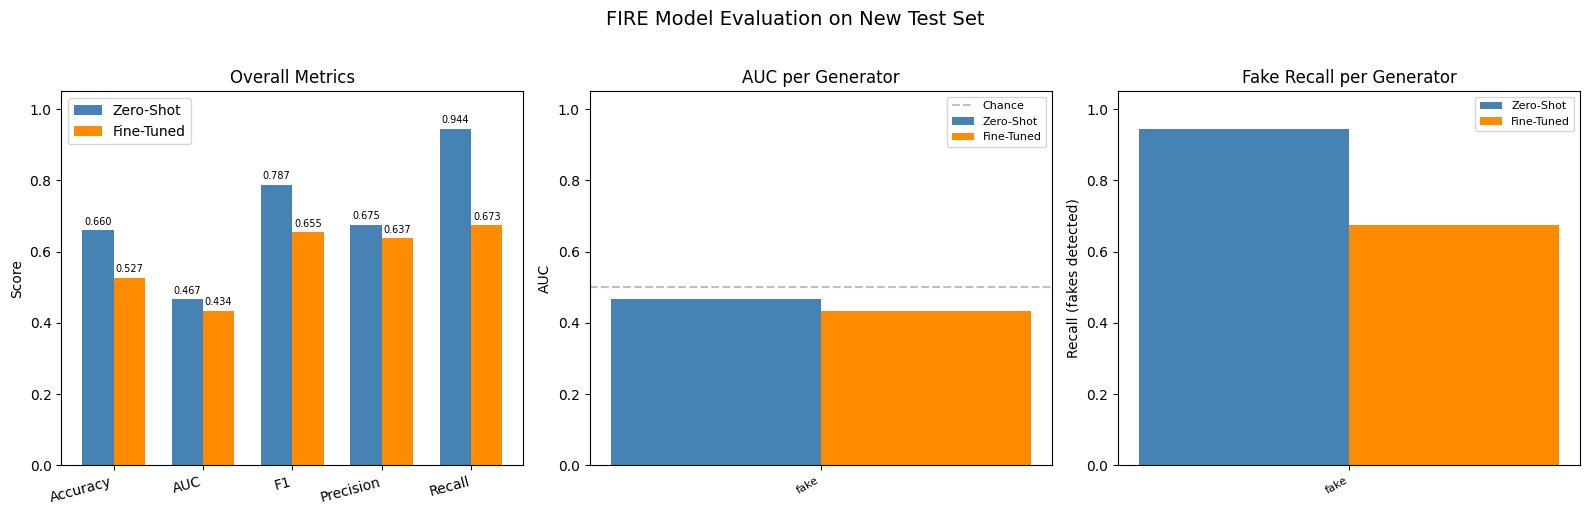

Plot saved: /content/eval_results/new_test_eval_plots.png


In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('FIRE Model Evaluation on New Test Set', fontsize=14, y=1.02)

# ── 1. Overall metric bars
ax = axes[0]
metric_names = ['Accuracy', 'AUC', 'F1', 'Precision', 'Recall']
vals_zs = [metrics_zs['acc'], metrics_zs['auc'], metrics_zs['f1'],
           metrics_zs['precision'], metrics_zs['recall']]
vals_ft = [metrics_ft['acc'], metrics_ft['auc'], metrics_ft['f1'],
           metrics_ft['precision'], metrics_ft['recall']]
x = np.arange(len(metric_names))
w = 0.35
ax.bar(x - w/2, vals_zs, w, label='Zero-Shot',  color='steelblue')
ax.bar(x + w/2, vals_ft, w, label='Fine-Tuned', color='darkorange')
ax.set_xticks(x)
ax.set_xticklabels(metric_names, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.set_title('Overall Metrics')
ax.legend()
ax.set_ylabel('Score')
for i, (v_zs, v_ft) in enumerate(zip(vals_zs, vals_ft)):
    ax.text(i - w/2, v_zs + 0.01, f'{v_zs:.3f}', ha='center', va='bottom', fontsize=7)
    ax.text(i + w/2, v_ft + 0.01, f'{v_ft:.3f}', ha='center', va='bottom', fontsize=7)

# ── 2. Per-generator AUC comparison
ax = axes[1]
if len(gen_df_zs) > 0 and len(gen_df_ft) > 0:
    merged = gen_df_zs[['generator','auc']].rename(columns={'auc':'auc_zs'}).merge(
             gen_df_ft[['generator','auc']].rename(columns={'auc':'auc_ft'}),
             on='generator', how='outer')
    gens = merged['generator'].tolist()
    x2 = np.arange(len(gens))
    ax.bar(x2 - w/2, merged['auc_zs'].fillna(0), w, label='Zero-Shot',  color='steelblue')
    ax.bar(x2 + w/2, merged['auc_ft'].fillna(0), w, label='Fine-Tuned', color='darkorange')
    ax.set_xticks(x2)
    ax.set_xticklabels(gens, rotation=30, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='Chance')
    ax.set_title('AUC per Generator')
    ax.legend(fontsize=8)
    ax.set_ylabel('AUC')

# ── 3. Per-generator Fake Recall
ax = axes[2]
if len(gen_df_zs) > 0 and len(gen_df_ft) > 0:
    merged2 = gen_df_zs[['generator','fake_recall']].rename(columns={'fake_recall':'fr_zs'}).merge(
              gen_df_ft[['generator','fake_recall']].rename(columns={'fake_recall':'fr_ft'}),
              on='generator', how='outer')
    x3 = np.arange(len(merged2))
    ax.bar(x3 - w/2, merged2['fr_zs'].fillna(0), w, label='Zero-Shot',  color='steelblue')
    ax.bar(x3 + w/2, merged2['fr_ft'].fillna(0), w, label='Fine-Tuned', color='darkorange')
    ax.set_xticks(x3)
    ax.set_xticklabels(merged2['generator'].tolist(), rotation=30, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title('Fake Recall per Generator')
    ax.legend(fontsize=8)
    ax.set_ylabel('Recall (fakes detected)')

plt.tight_layout()
plot_path = '/content/eval_results/new_test_eval_plots.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved: {plot_path}')